# Блок 1. Формулировка задачи

Представьте, что нам прислали запись из полевого журнала. Пингвина взвесили, измерили клюв и ласт, записали остров и пол. Графа «Вид» осталась пустой. Сможем её заполнить по этим данным?

В [Palmer Penguins](https://huggingface.co/datasets/SIH/palmer-penguins) есть 344 наблюдения, для которых вид уже известен. В таблице он записан в столбце `species`. Возможных ответов три.

![Три вида пингвинов: Adelie, Chinstrap и Gentoo](assets/penguin-species.jpg)

*Слева направо: Adelie, Chinstrap и Gentoo.*

Модель будет выбирать один из трёх видов. Это задача **многоклассовой классификации**. Сначала посмотрим, различаются ли виды по замерам. Потом дадим эти замеры двум моделям и выясним, кого они чаще путают. В конце вернёмся к записи из полевого журнала.

---

# Блок 2. Загрузка и первичный осмотр

<table width="100%" style="width: 100%; max-width: 960px; table-layout: fixed; text-align: center;">
  <tr>
    <td colspan="3"><img src="assets/library-workflow.jpg" width="960" alt="Три рисунка из полевого журнала: загрузка набора, таблица замеров и график"></td>
  </tr>
  <tr>
    <td width="33%" align="center"><strong>Загружаем набор</strong><br><code>datasets</code><br><code>load_dataset(...)</code></td>
    <td width="34%" align="center"><strong>Смотрим таблицу</strong><br><code>pandas</code><br><code>.to_pandas()</code></td>
    <td width="33%" align="center"><strong>Строим графики</strong><br><code>seaborn</code> и <code>matplotlib</code><br><code>sns.scatterplot(...)</code></td>
  </tr>
</table>

Одна и та же запись сегодня будет строкой в таблице, точкой на графике и набором чисел для модели. Начнём с таблицы.

### Подготовим окружение

Эта ячейка задаёт путь к кэшу и подключает библиотеки. Если какой-то библиотеки нет, выполните команду `%pip` из комментария в отдельной ячейке.

Скачанные файлы и подготовленная таблица сохраняются в `.cache/huggingface` рядом с ноутбуком.

In [1]:
# При необходимости выполните в отдельной ячейке:
# %pip install datasets pandas matplotlib seaborn scikit-learn

import os
from pathlib import Path

seminar_dir = Path.cwd()
repo_seminar_dir = seminar_dir / "practices" / "ML_Lifecycle"
if (repo_seminar_dir / "1.ipynb").is_file():
    seminar_dir = repo_seminar_dir

# Hugging Face читает эти пути при импорте.
hf_cache = seminar_dir / ".cache" / "huggingface"
os.environ["HF_HUB_CACHE"] = str(hf_cache / "hub")
os.environ["HF_DATASETS_CACHE"] = str(hf_cache / "datasets")
os.environ["HF_XET_CACHE"] = str(hf_cache / "xet")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from IPython.display import display
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
species_order = ["Adelie", "Chinstrap", "Gentoo"]
species_palette = dict(zip(species_order, ["#2563a6", "#b35716", "#22775d"]))

---

### Загрузим данные

На Hugging Face весь набор лежит в одной части с названием `train`. Откроем её через `load_dataset` и превратим в таблицу с помощью `.to_pandas()`. Названия столбцов берём из схемы набора. В коде сразу проверяем, что все нужные столбцы на месте.

Дальше разделим таблицу примерно 70/30. В `stratify` передаём столбец `species`, чтобы сохранить похожие доли видов в обеих частях. `random_state=42` позволяет повторить то же разбиение. Из тестовой части возьмём одну запись для карточки и пока оставим её вид за кадром.

In [2]:
dataset_dict = load_dataset("SIH/palmer-penguins")
penguins_dataframe = dataset_dict["train"].to_pandas()

target_column = "species"
feature_columns = [
    "bill_length_mm", "bill_depth_mm", "flipper_length_mm",
    "body_mass_g", "island", "sex",
]
missing_columns = set([target_column, *feature_columns]) - set(penguins_dataframe.columns)
if missing_columns:
    raise ValueError(f"В датасете отсутствуют столбцы: {sorted(missing_columns)}")

# Разбиение совпадает с тем, которое дальше используем для обучения.
eda_train, eda_test = train_test_split(
    penguins_dataframe, test_size=0.3, random_state=42,
    stratify=penguins_dataframe[target_column],
)
field_example = eda_test[feature_columns].dropna().iloc[0]

print(
    f"{len(penguins_dataframe)} наблюдения · "
    f"{penguins_dataframe.shape[1]} столбцов · "
    f"{penguins_dataframe[target_column].nunique()} вида"
)

README.md: 0.00B [00:00, ?B/s]

c:\Prgrm\Intro_in_ML\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Prgrm\Intro_in_ML\practices\ML_Lifecycle\.cache\huggingface\hub\datasets--SIH--palmer-penguins. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


penguins.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/344 [00:00<?, ? examples/s]

344 наблюдения · 8 столбцов · 3 вида


---

### Полевое наблюдение

![Пингвин на берегу Антарктики, вид со спины](assets/penguin-field.jpg)

*Замеры ниже взяты из тестовой выборки.*

Запомним эту карточку. В конце посмотрим, какой вид модель предложит для этих замеров.

In [3]:
field_card = pd.Series({
    "Длина клюва": f"{field_example['bill_length_mm']:g} мм",
    "Глубина клюва": f"{field_example['bill_depth_mm']:g} мм",
    "Длина ласта": f"{field_example['flipper_length_mm']:g} мм",
    "Масса тела": f"{field_example['body_mass_g']:g} г",
    "Остров": field_example["island"],
    "Пол": {"male": "самец", "female": "самка"}.get(field_example["sex"], field_example["sex"]),
    "Вид": "?",
}, name="Полевое наблюдение")

display(field_card.to_frame())

,Полевое наблюдение
Длина клюва,50.7 мм
Глубина клюва,15 мм
Длина ласта,223 мм
Масса тела,5550 г
Остров,Biscoe
Пол,самец
Вид,?


---

### Посмотрим на первые строки

Вот как выглядят записи, на которых будем учиться. В обычных обозначениях `X` — признаки, которые мы подаём модели, а `y` — известные ответы из `species`. Если по ошибке положить `species` в `X`, модель увидит ответ прямо во входной строке.

Год оставим в таблице для справки. В этой задаче используем четыре замера, остров и пол.

In [4]:
display(eda_train[[*feature_columns, target_column, "year"]].head())

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,species,year
36,38.8,20.0,190.0,3950.0,Dream,male,Adelie,2007
19,46.0,21.5,194.0,4200.0,Torgersen,male,Adelie,2007
192,42.7,13.7,208.0,3950.0,Biscoe,female,Gentoo,2008
109,43.2,19.0,197.0,4775.0,Biscoe,male,Adelie,2009
89,38.9,18.8,190.0,3600.0,Dream,female,Adelie,2008


Пять строк дают представление о таблице. Теперь проверим, что происходит в остальных записях обучающей выборки.

---

# Блок 3. Первичная диагностика данных

### Пропуски

На графике считаем пустые ячейки по столбцам. В коде `.isna()` отмечает пропуски, а `.sum()` их складывает. Число строк с пропусками считаем отдельно. У одного пингвина могут отсутствовать сразу несколько замеров. В примере под графиком пропуск показан прочерком.

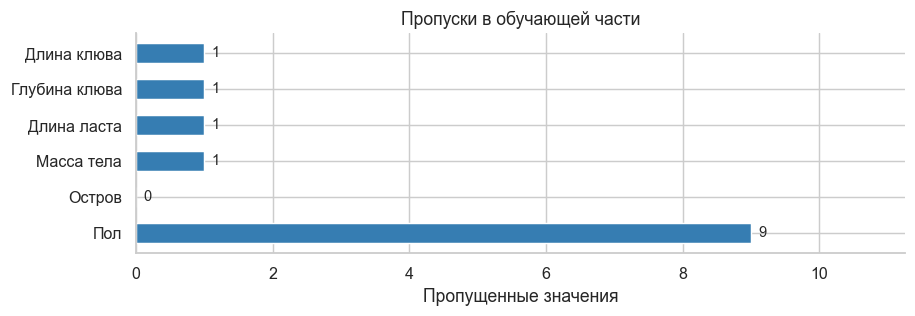

Строк с пропусками: 9 из 240.


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex
47,37.5,18.9,179.0,2975.0,Dream,—


In [5]:
training_features = eda_train[feature_columns]
missing_counts = training_features.isna().sum()
incomplete_rows = training_features.isna().any(axis=1)

fig, ax = plt.subplots(figsize=(8.6, 2.9), dpi=105, layout="constrained")
labels = ["Длина клюва", "Глубина клюва", "Длина ласта", "Масса тела", "Остров", "Пол"]
bars = ax.barh(labels, missing_counts, color="#367db2", height=.56)
ax.bar_label(bars, padding=5, fontsize=10)
ax.invert_yaxis()
ax.set(xlim=(0, max(1, missing_counts.max()) * 1.25),
       xlabel="Пропущенные значения", title="Пропуски в обучающей части")
ax.xaxis.get_major_locator().set_params(integer=True)
sns.despine(ax=ax)
plt.show()

print(f"Строк с пропусками: {incomplete_rows.sum()} из {len(training_features)}.")
display(training_features.loc[incomplete_rows].head(1).fillna("—"))

---

### Числовые и категориальные признаки

Массу или длину клюва можно сравнить, усреднить или перевести в другой масштаб. С островом и полом так не получится. Это названия категорий. Позже мы закодируем их отдельно.

В ячейке `select_dtypes` находит числовые столбцы. Из остальных признаков здесь только `island` и `sex`. А для числовых замеров сразу выведем минимум, среднее и максимум, чтобы проверить диапазоны.

In [6]:
numeric_columns = training_features.select_dtypes(include="number").columns.tolist()
categorical_columns = training_features.select_dtypes(exclude="number").columns.tolist()

print("Числовые признаки:", ", ".join(numeric_columns))
print("Категориальные признаки:", ", ".join(categorical_columns))

summary_labels = dict(zip(numeric_columns, [
    "Длина клюва, мм", "Глубина клюва, мм", "Длина ласта, мм", "Масса тела, г"
]))
display(
    training_features[numeric_columns].describe().T[["min", "mean", "max"]]
    .rename(index=summary_labels, columns={"min": "Мин.", "mean": "Среднее", "max": "Макс."})
    .round(1)
)

Числовые признаки: bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g
Категориальные признаки: island, sex


,Мин.,Среднее,Макс.
"Длина клюва, мм",33.1,44.1,59.6
"Глубина клюва, мм",13.1,17.2,21.5
"Длина ласта, мм",172.0,201.1,231.0
"Масса тела, г",2700.0,4233.7,6300.0


В сводке выше масса лежит примерно между **2,7 и 6,3 кг**. Если бы в этой колонке встретилось 30 000 г, я бы сначала проверил исходную запись и единицы измерения. Для этого и смотрим на минимум и максимум до обучения.

---

### Какие виды представлены чаще?

В `train` 106 Adelie из 240. Если всегда отвечать «Adelie», получится угадать примерно 44% записей. Держим это число в уме, когда дойдём до первой модели.

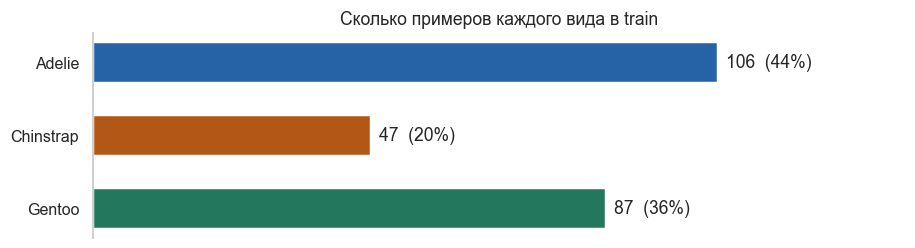

In [7]:
class_counts = eda_train[target_column].value_counts().reindex(species_order)

fig, ax = plt.subplots(figsize=(8.6, 2.25), dpi=105, layout="constrained")
bars = ax.barh(species_order, class_counts, color=[species_palette[s] for s in species_order], height=.55)
ax.bar_label(bars, labels=[f"{n}  ({n / class_counts.sum():.0%})" for n in class_counts], padding=6)
ax.invert_yaxis()
ax.set(xlim=(0, class_counts.max() * 1.3), title="Сколько примеров каждого вида в train")
ax.tick_params(axis="x", bottom=False, labelbottom=False)
ax.grid(False)
sns.despine(ax=ax, bottom=True)
plt.show()

---

### Можно ли различить виды по замерам?

Одна точка — один пингвин. Цвет и форма показывают вид. Слева смотрим на клюв, справа — на ласт и массу. Сравните, где точки разных видов накладываются друг на друга.

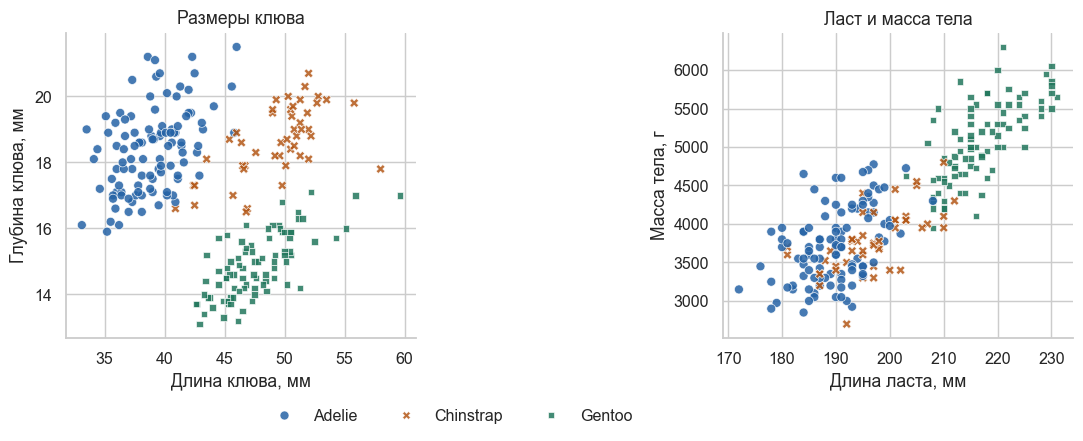

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.05), dpi=105, layout="constrained")
panels = [
    ("bill_length_mm", "bill_depth_mm", "Размеры клюва", "Длина клюва, мм", "Глубина клюва, мм"),
    ("flipper_length_mm", "body_mass_g", "Ласт и масса тела", "Длина ласта, мм", "Масса тела, г"),
]
for ax, (x, y, title, xlabel, ylabel) in zip(axes, panels):
    sns.scatterplot(
        data=eda_train, x=x, y=y, hue=target_column, style=target_column,
        hue_order=species_order, style_order=species_order, palette=species_palette,
        s=38, alpha=.85, legend=(ax is axes[0]), ax=ax,
    )
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    sns.despine(ax=ax)

sns.move_legend(axes[0], "lower center", bbox_to_anchor=(1.1, -.33),
                ncol=3, title=None, frameon=False)
plt.show()

**На каком графике проще отличить Adelie от Chinstrap?**

<details>
<summary>Разбор графиков</summary>

У Adelie и Chinstrap больше перекрытия на графике справа. По двум размерам клюва их разделить проще. Модели дальше дадим все четыре замера сразу.

</details>

---

# Блок 4. Подготовка данных

### Что делать с неполной строкой?

Вернёмся к записи с индексом 47. Пол пингвина не записан, зато все четыре замера на месте. Если выбросить эту строку целиком, потеряем и замеры. Для наших моделей заполним пропуски и посмотрим, что именно окажется в таблице.

Для чисел возьмём **медиану**. Она лежит в середине упорядоченных значений, поэтому один странный замер обычно сдвинет её меньше, чем среднее. Для категорий возьмём **моду**, то есть самый частый ответ в столбце. В строку 47 поэтому попадёт `male`. Это значение для работы модели. Какой пол был у пингвина на самом деле, по этой строке мы по-прежнему не знаем.

In [9]:
import numpy as np
from sklearn.base import clone
from sklearn.impute import SimpleImputer

features_train = eda_train[feature_columns].fillna(np.nan)
features_test = eda_test[feature_columns].fillna(np.nan)
target_train = eda_train[target_column]
target_test = eda_test[target_column]

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

complete_count = len(features_train.dropna())
display(pd.DataFrame({
    "Наблюдений в train": [complete_count, len(features_train)],
    "Удалено строк": [len(features_train) - complete_count, 0],
}, index=["Удалить неполные строки", "Заполнить пропуски"]))

example_row = features_train.loc[incomplete_rows].iloc[[0]]
filled_row = pd.concat([
    pd.DataFrame(
        clone(numeric_imputer).fit(features_train[numeric_columns])
        .transform(example_row[numeric_columns]),
        columns=numeric_columns, index=example_row.index,
    ),
    pd.DataFrame(
        clone(categorical_imputer).fit(features_train[categorical_columns])
        .transform(example_row[categorical_columns]),
        columns=categorical_columns, index=example_row.index,
    ),
], axis=1)

replacement_rule = {
    **dict.fromkeys(numeric_columns, "Медиана в train"),
    **dict.fromkeys(categorical_columns, "Самая частая категория в train"),
}
comparison = pd.DataFrame({
    "До": example_row.iloc[0],
    "После": filled_row.iloc[0],
    "Что сделали": [
        replacement_rule[column] if example_row[column].isna().iloc[0] else "Сохранили"
        for column in feature_columns
    ],
}).rename(index={
    "bill_length_mm": "Длина клюва, мм",
    "bill_depth_mm": "Глубина клюва, мм",
    "flipper_length_mm": "Длина ласта, мм",
    "body_mass_g": "Масса тела, г",
    "island": "Остров",
    "sex": "Пол",
})
display(comparison.fillna("—"))

,Наблюдений в train,Удалено строк
Удалить неполные строки,231,9
Заполнить пропуски,240,0


,До,После,Что сделали
"Длина клюва, мм",37.5,37.5,Сохранили
"Глубина клюва, мм",18.9,18.9,Сохранили
"Длина ласта, мм",179.0,179.0,Сохранили
"Масса тела, г",2975.0,2975.0,Сохранили
Остров,Dream,Dream,Сохранили
Пол,—,male,Самая частая категория в train


Из первой таблицы видно, что при удалении теряем **9 строк из 240**. Во второй таблице видно, что именно меняется при заполнении: в записи 47 появилось значение пола, а замеры остались прежними.

---

### Откуда берём правила заполнения?

В Palmer Penguins есть записи, где вид известен, а массы в таблице нет. Такое бывает, например, если пингвина не удалось взвесить. Когда масса указана, берём сам замер. При пропуске подставляем медиану из `train`. В нашем примере это **4 100 г**.

Допустим, на тесте пингвины в среднем тяжелее. Если взять их в расчёт, они могут сдвинуть медиану и повлиять на подготовку признаков. Это утечка данных. Для проверки мы хотим воспроизвести обычную ситуацию, когда новая запись приходит уже после обучения.

![На train вычисляем правила подготовки и обучаем модель. На test применяем готовые правила и получаем прогноз.](assets/train-test-preprocessing.svg)

На верхней дорожке вызов `fit` у пайплайна вычисляет параметры подготовки и обучает модель. По пунктирным стрелкам вниз передаём то, что получилось. Даже полная запись проходит через `transform`. Например, её массу надо перевести в тот же масштаб, в котором модель видела массы при обучении.

---

# Блок 5. Кодирование признаков и сравнение моделей

### Как модель увидит замеры и названия островов

Два пингвина могут отличаться по массе на 300 граммов, а по длине клюва на 5 миллиметров. Если kNN посчитает расстояние по этим числам как есть, масса почти наверняка перевесит клюв просто из-за единиц измерения. Поэтому после заполнения пропусков применим `StandardScaler`. Для каждого числового столбца вычтем его среднее по подготовленному `train` и разделим на стандартное отклонение.

С островами другая история. Если дать Biscoe, Dream и Torgersen номера 0, 1 и 2, для kNN получится, будто расстояние от Biscoe до Dream вдвое меньше, чем от Biscoe до Torgersen. Эти расстояния мы бы придумали сами. Поэтому `OneHotEncoder` выделит каждому острову свой столбец с нулями и единицами. Если попадётся неизвестный остров, все индикаторы островов будут нулевыми.

`ColumnTransformer` говорит, какие столбцы идут в каждую ветку. `Pipeline` задаёт порядок действий. Например, в числовой ветке сначала заполняем пропуски, потом масштабируем.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay

numeric_transformer = Pipeline([
    ("impute", numeric_imputer),
    ("scale", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("impute", categorical_imputer),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_columns),
    ("categorical", categorical_transformer, categorical_columns),
], verbose_feature_names_out=False)

---

### Найдём ту же запись после обработки

Здесь сделаем пробный прогон на копии предобработки. Когда начнём сравнивать модели, правила подготовки будут вычисляться заново в каждом раунде.

У строки 47 остров Dream, поэтому в `island_Dream` стоит единица, а в двух соседних столбцах островов — нули. Число **−1,58** в столбце массы тоже можно прочитать. Пингвин весил 2 975 г, среднее после заполнения пропусков в `train` около 4 233 г, стандартное отклонение около 798 г. Получаем $(2975 - 4233) / 798 \approx -1{,}58$.

На этой строке виден смысл отдельного числа. А в нижней таблице уже смотрим на столбцы целиком. У преобразованных числовых столбцов средние близки к нулю, стандартные отклонения — к единице.

In [11]:
# Отдельная копия для показа. При обучении модели пайплайн подгонит свои шаги.
demo_preprocessor = clone(preprocessor)
transformed_train = pd.DataFrame(
    demo_preprocessor.fit_transform(features_train),
    columns=demo_preprocessor.get_feature_names_out(),
    index=features_train.index,
)

print(f"Признаков до обработки: {features_train.shape[1]}. После: {transformed_train.shape[1]}.")
display(transformed_train.loc[example_row.index].round(2))

scaled_train = transformed_train[numeric_columns]
display(pd.DataFrame({
    "Среднее в train": scaled_train.mean(),
    "Стандартное отклонение в train": scaled_train.std(ddof=0),
}).round(2))

Признаков до обработки: 6. После: 9.


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_female,sex_male
47,-1.2,0.85,-1.58,-1.58,0.0,1.0,0.0,0.0,1.0


,Среднее в train,Стандартное отклонение в train
bill_length_mm,-0.0,1.0
bill_depth_mm,0.0,1.0
flipper_length_mm,-0.0,1.0
body_mass_g,0.0,1.0


---

### Три способа ответить на один вопрос

На графике выше мы уже видели, что Adelie встречается чаще всего. Дадим этот приём `DummyClassifier`: на каждом разбиении он будет отвечать самым частым видом в своей обучающей части. С его результатом и сравним модели, которые используют замеры.

Дальше попробуем **логистическую регрессию** и **kNN**. Логистическая регрессия учится оценивать вероятность каждого вида по признакам и выбирает вид с наибольшей оценкой. kNN действует иначе. Он ищет пять ближайших обучающих наблюдений и смотрит, за какой вид они голосуют.

![Схема kNN: из пяти ближайших соседей три относятся к Adelie, два к Chinstrap](assets/knn-five-neighbors.svg)

В этом условном примере три соседа голосуют за Adelie, два за Chinstrap. Мы используем два признака, чтобы показать идею на плоскости. В эксперименте kNN считает расстояния по всем преобразованным признакам.

---

### Как сравнить модели до финального теста?

У нас 240 строк в `train`. Делим их на пять частей с похожими долями видов. В первом раунде учимся на 192 строках, проверяем на оставшихся 48. В следующем меняем проверочную часть. После пяти раундов каждая часть один раз побывала на проверке, а у всех моделей были одни и те же разбиения.

Медианы, масштабы и категории пайплайн заново вычисляет в каждом раунде, на его 192 обучающих строках. Те 48 строк, на которых проверяем результат, в этот расчёт не входят.

**Accuracy** — доля верных ответов по всем записям. Для выбора модели возьмём **F1-macro**. Он считает F1 отдельно по каждому виду, а потом берёт обычное среднее. Так результат по менее частому Chinstrap влияет на выбор столько же, сколько результат по Adelie.

,Accuracy,F1-macro,Разброс F1-macro (σ)
Модель,,,
Частый класс,0.442,0.204,0.003
Логистическая регрессия,0.992,0.990,0.013
kNN (k=5),0.988,0.985,0.013


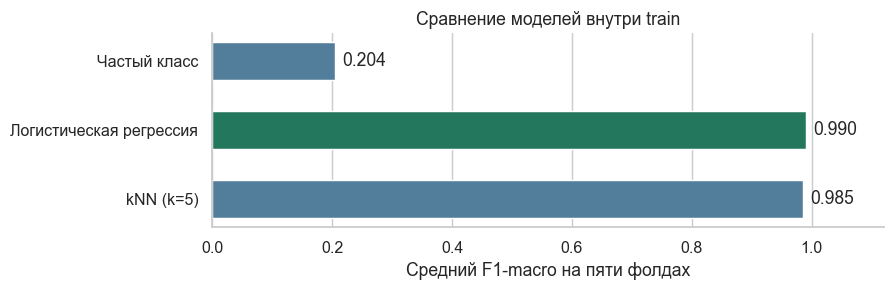

Лучшая модель на текущих признаках: Логистическая регрессия.


In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Частый класс": DummyClassifier(strategy="most_frequent"),
    "Логистическая регрессия": LogisticRegression(max_iter=1000),
    "kNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
fold_f1_by_model = {}
for name, classifier in models.items():
    candidate = Pipeline([
        ("prepare", clone(preprocessor)),
        ("classifier", clone(classifier)),
    ])
    scores = cross_validate(
        candidate, features_train, target_train, cv=cv,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        error_score="raise",
    )
    fold_f1_by_model[name] = scores["test_f1_macro"]
    results.append({
        "Модель": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "F1-macro": scores["test_f1_macro"].mean(),
        "Разброс F1-macro (σ)": scores["test_f1_macro"].std(),
    })

cv_results = pd.DataFrame(results).set_index("Модель")
selected_name = cv_results["F1-macro"].idxmax()
display(cv_results.round(3))

fig, ax = plt.subplots(figsize=(8.4, 2.65), dpi=105, layout="constrained")
colors = ["#22775d" if name == selected_name else "#527e9b" for name in cv_results.index]
bars = ax.barh(cv_results.index, cv_results["F1-macro"], height=.55, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.invert_yaxis()
ax.set(xlim=(0, 1.12), xlabel="Средний F1-macro на пяти фолдах", title="Сравнение моделей внутри train")
ax.set_xticks(np.linspace(0, 1, 6))
ax.grid(axis="y", visible=False)
sns.despine(ax=ax)
plt.show()

print(f"Лучшая модель на текущих признаках: {selected_name}.")

На графике у логистической регрессии и kNN столбики почти одной длины. В последнем столбце таблицы над графиком видно, насколько оценка менялась от фолда к фолду. По нашему правилу выигрывает логистическая регрессия. Разница в средних небольшая, поэтому запомним, что это результат конкретного сравнения на пяти фолдах.

---

### Ещё один круг. Что даёт модели остров?

До сих пор меняли модель, а признаки оставляли прежними. Теперь поменяем один признак. Название острова может многое подсказать о виде. В первой таблице посмотрим, как виды действительно распределены по островам в train.

![Один оборот эксперимента: наблюдение в train, гипотеза об острове, изменение признаков и повторная валидация на тех же фолдах](assets/island-experiment-loop.svg)

Что изменится, если обучить ту же модель вообще без названия острова? Сравним два варианта на тех же пяти фолдах. Изменим только набор признаков.

In [13]:
from sklearn.model_selection import cross_val_score

island_counts = pd.crosstab(eda_train["island"], target_train).reindex(columns=species_order)
display(island_counts.rename_axis(index="Остров", columns="Вид"))

without_island = ColumnTransformer([
    ("numeric", clone(numeric_transformer), numeric_columns),
    ("categorical", clone(categorical_transformer), ["sex"]),
], verbose_feature_names_out=False)

without_island_pipeline = Pipeline([
    ("prepare", clone(without_island)),
    ("classifier", clone(models[selected_name])),
])
without_island_scores = cross_val_score(
    without_island_pipeline, features_train, target_train,
    cv=cv, scoring="f1_macro", error_score="raise",
)

feature_comparison = pd.DataFrame({
    "С островом": fold_f1_by_model[selected_name],
    "Без острова": without_island_scores,
}, index=pd.Index(range(1, cv.get_n_splits() + 1), name="Фолд"))
feature_comparison.loc["Среднее"] = feature_comparison.mean()
display(feature_comparison.round(3))

selected_features = feature_comparison.loc["Среднее"].idxmax()
final_preprocessor = preprocessor if selected_features == "С островом" else without_island
print(f"Для итоговой проверки выбрали вариант: {selected_features.lower()}.")

Вид,Adelie,Chinstrap,Gentoo
Остров,,,
Biscoe,29,0,87
Dream,39,47,0
Torgersen,38,0,0


,С островом,Без острова
Фолд,,
1,0.973,0.973
2,1.000,0.943
3,1.000,1.000
4,1.000,1.000
5,0.975,0.975
Среднее,0.990,0.978


Для итоговой проверки выбрали вариант: с островом.


### Что изменилось?

В нашем `train` все Gentoo оказались на Biscoe, а все Chinstrap — на Dream. В нижней таблице обратите внимание на второй фолд. С островом получили **1,000**, без острова — **0,943**. Остальные четыре строки совпали.

Для итогового теста оставляем остров. Он немного поднял средний F1-macro на этих пяти фолдах. Для полевых записей с нового острова это придётся проверить отдельно.

---

# Блок 6. Итоговая проверка и разбор ошибок

### Один раз проверим выбранную модель на test

Выбор сделали. Теперь берём все **240 строк `train`** и вызываем `fit`. Пайплайн готовит признаки и на них обучает классификатор. В `predict` подаём сырые признаки **104 строк `test`**. Пайплайн сам применит те же преобразования и вернёт прогнозы. Дальше сверим их с известными видами.

**Precision** отвечает на вопрос «Из всех, кого модель назвала Adelie, сколько действительно были Adelie?». **Recall** отвечает на другой вопрос «Из всех настоящих Adelie сколько модель нашла?». **F1** объединяет эти две оценки в гармоническое среднее. **Support** показывает, сколько наблюдений данного вида было в тесте.

In [14]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

full_pipeline = Pipeline([
    ("prepare", clone(final_preprocessor)),
    ("classifier", clone(models[selected_name])),
])
full_pipeline.fit(features_train, target_train)
test_predictions = pd.Series(
    full_pipeline.predict(features_test), index=target_test.index, name="Прогноз",
)

correct_count = int(test_predictions.eq(target_test).sum())
test_accuracy = accuracy_score(target_test, test_predictions)
test_f1_macro = f1_score(target_test, test_predictions, average="macro")

print(f"Модель: {selected_name}")
print(f"Верных ответов: {correct_count} из {len(target_test)}")
print(f"Accuracy: {test_accuracy:.3f} · F1-macro: {test_f1_macro:.3f}")

report = classification_report(
    target_test, test_predictions, labels=species_order, output_dict=True, zero_division=0,
)
report_table = pd.DataFrame(report).T.loc[
    [*species_order, "macro avg", "weighted avg"],
    ["precision", "recall", "f1-score", "support"],
].rename(index={"macro avg": "Среднее по видам", "weighted avg": "Среднее по наблюдениям"})
report_table["support"] = report_table["support"].astype(int)
display(report_table.round(3))

Модель: Логистическая регрессия
Верных ответов: 103 из 104
Accuracy: 0.990 · F1-macro: 0.992


,precision,recall,f1-score,support
Adelie,0.979,1.000,0.989,46
Chinstrap,1.000,1.000,1.000,21
Gentoo,1.000,0.973,0.986,37
Среднее по видам,0.993,0.991,0.992,104
Среднее по наблюдениям,0.991,0.990,0.990,104


В отчёте две строки со средними. В «Среднем по видам» Adelie и Chinstrap имеют одинаковый вес. В «Среднем по наблюдениям» результат по Adelie весит больше, потому что в тесте 46 Adelie и 21 Chinstrap.

<details>
<summary>Формулы для отчёта по классам</summary>

Для выбранного вида TP — верные ответы этого вида, FP — чужие объекты, отнесённые к нему, FN — объекты этого вида, которые модель пропустила.

- **Precision** $= TP / (TP + FP)$.
- **Recall** $= TP / (TP + FN)$.
- **F1** $= 2 \cdot \mathrm{precision} \cdot \mathrm{recall} / (\mathrm{precision} + \mathrm{recall})$.

</details>

---

### Кого с кем перепутала модель?

На матрице сначала найдём строку с **истинным видом**, потом столбец с **прогнозом**. Если названия совпали, мы на диагонали и ответ верный. Теперь поищем число вне диагонали. Строка скажет, кто это был, столбец — за кого его приняли.

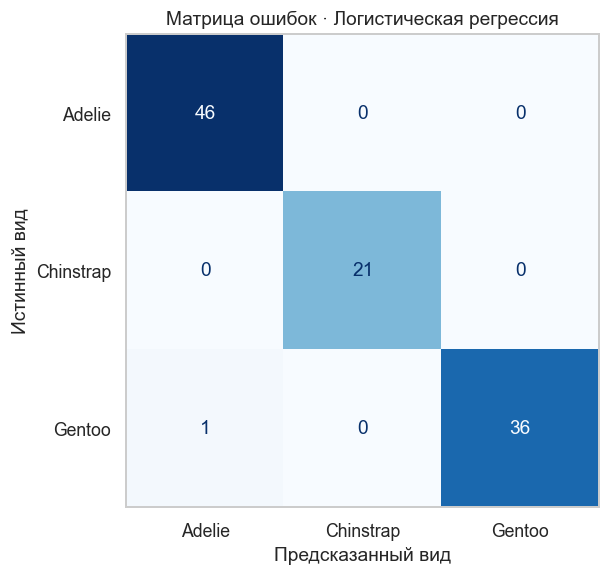

Один пример ошибки из теста:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,Истинный вид,Предсказанный вид
271,NaN,NaN,NaN,NaN,Biscoe,NaN,Gentoo,Adelie


In [15]:
fig, ax = plt.subplots(figsize=(6.6, 4.9), dpi=115, layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    target_test, test_predictions, labels=species_order,
    cmap="Blues", colorbar=False, ax=ax,
)
ax.set(
    title=f"Матрица ошибок · {selected_name}",
    xlabel="Предсказанный вид", ylabel="Истинный вид",
)
ax.grid(False)
plt.show()

test_results = features_test.assign(
    Истинный_вид=target_test, Предсказанный_вид=test_predictions,
)
error_rows = test_results.loc[test_predictions.ne(target_test)]
if error_rows.empty:
    print("На этой тестовой выборке ошибок нет.")
else:
    print("Один пример ошибки из теста:")
    display(error_rows.head(1).rename(columns={
        "Истинный_вид": "Истинный вид", "Предсказанный_вид": "Предсказанный вид",
    }))

В сохранённом прогоне смотрим на клетку **Gentoo → Adelie**. По строке видно, что из 37 настоящих Gentoo нашли 36. Это **recall Gentoo, 36/37**. Теперь читаем столбец Adelie. Модель назвала так 47 пингвинов, и 46 из них действительно Adelie. Это **precision Adelie, 46/47**. С одной и той же ошибкой сталкиваемся дважды, когда меняем вопрос.

В таблице под матрицей видна сама запись. Из признаков сохранился только остров. Четыре замера и пол пайплайн заполнил по правилам из `train`, поэтому у модели было мало фактической информации об этом пингвине.

---

### Вернёмся к полевой карточке

Откроем прогноз для записи, с которой начали. Он уже получен вместе с остальными прогнозами на тесте. Рядом поставим вид из полевого журнала.

In [16]:
field_result = field_card.drop("Вид").copy()
field_result["Прогноз модели"] = test_predictions.loc[field_example.name]
field_result["Вид в исходной записи"] = target_test.loc[field_example.name]
display(field_result.to_frame())

,Полевое наблюдение
Длина клюва,50.7 мм
Глубина клюва,15 мм
Длина ласта,223 мм
Масса тела,5550 г
Остров,Biscoe
Пол,самец
Прогноз модели,Gentoo
Вид в исходной записи,Gentoo


У первой карточки теперь есть прогноз, а у нас есть представление, когда ему можно доверять. Если следующая партия замеров придёт с другого острова, я бы начал с таблицы видов по островам. Возможно, тогда стоит снова проверить, оставлять ли `island` в признаках.